### Импорты

In [ ]:
import os
import joblib

import pandas as pd
import numpy as np

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.base import clone

import hw1.solution_utils as su

DATA_PATH = os.environ.get("HW1_DATA", "hw1_train.jsonl")

### Загрузка данных и чистка

In [2]:
dialogs = su.read_dialogs(DATA_PATH)

frame_all = su.to_frame(dialogs)
print("диалогов:", len(frame_all), " размечено по реакции:", frame_all.reaction.notna().sum())
df = frame_all[frame_all.reaction.notna()].reset_index(drop=True)
df[["dialog_id", "last_raw", "n_user", "reaction"]].head()


Обработано 1000 диалогов...
Обработано 2000 диалогов...
Обработано 3000 диалогов...
Обработано 4000 диалогов...
Обработано 5000 диалогов...
Обработано 6000 диалогов...
Обработано 7000 диалогов...
Обработано 8000 диалогов...
Обработано 9000 диалогов...
Обработано 10000 диалогов...
диалогов: 10000  размечено по реакции: 3000


,dialog_id,last_raw,n_user,reaction
0,d094012177e,"any spec symbols used in ""paradoxical arithmet...",7,positive
1,d306fbe61fe,Give me GUI for this portion,8,neutral
2,dd6905952c7,1.Alex was at the supermarket when a fan bumpe...,5,neutral
3,d767a675896,recalculate everything considering the porport...,6,negative
4,d7a6280ce8e,how many masses we have on spectrometer,8,negative


### Разбиение

In [3]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(df, df.reaction, df.group))
train, test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("train:", len(train), train.reaction.value_counts(normalize=True).round(3).to_dict())
print("test: ", len(test), test.reaction.value_counts(normalize=True).round(3).to_dict())
print("общих групп:", len(set(train.group) & set(test.group)))

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 2)
outer_folds = list(outer_cv.split(train, train.reaction, train.group))

def nested_cv(name):
    """Вложенная кросс-валидация: внутри каждого внешнего фолда GridSearchCV подбирает параметры."""
    pipe, grid = MODELS[name]
    oof = np.empty(len(train), dtype=object); chosen = []
    for fit_idx, val_idx in outer_folds:
        fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
        if grid:
            search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
            search.fit(fit_part, fit_part.reaction, groups=fit_part.group)
            model, best = search.best_estimator_, search.best_params_
        else:
            model, best = clone(pipe).fit(fit_part, fit_part.reaction), {}
        oof[val_idx] = model.predict(val_part); chosen.append(best)
    return oof, chosen

train: 2400 {'neutral': 0.591, 'negative': 0.308, 'positive': 0.101}
test:  600 {'neutral': 0.592, 'negative': 0.308, 'positive': 0.1}
общих групп: 0


### Создание базовых и своих моделей, задача 1

In [7]:
MODELS = su.reaction_models()
METRIC_TABLE_COLS = ["model", "macro_f1", "macro_f1_bal", "accuracy",
        "balanced_acc", "R_negative", "R_neutral", "R_positive", "F1_positive"]

### Метрики на train (из кросс валидации)

In [8]:
rows, oof, params = [], {}, {}
for name in MODELS:
    oof[name], params[name] = nested_cv(name)
    rows.append({"model": name, **su.reaction_metrics(train.reaction, oof[name])})

cv_table = pd.DataFrame(rows)[METRIC_TABLE_COLS].round(3)
su.show_table(cv_table)

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,dummy_most_frequent,0.248,0.167,0.591,0.333,0.000,1.000,0.000,0.000
1,nb,0.480,0.415,0.661,0.480,0.554,0.819,0.066,0.120
2,logreg,0.569,0.535,0.674,0.551,0.556,0.800,0.296,0.370
3,linear_svm,0.580,0.529,0.694,0.550,0.528,0.853,0.267,0.385
4,nb_my,0.587,0.538,0.693,0.559,0.606,0.813,0.259,0.387
5,logreg_my,0.631,0.603,0.720,0.613,0.627,0.825,0.387,0.459
6,linear_svm_my,0.613,0.559,0.727,0.580,0.573,0.883,0.284,0.408


### Финальное обучение, итоговый подбор гиперпараметров на внутренней кросс-валидации

In [9]:
fitted = {n: (GridSearchCV(p, g, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
              .fit(train, train.reaction, groups=train.group).best_estimator_
              if g else clone(p).fit(train, train.reaction))
          for n, (p, g) in MODELS.items()}

test_pred = {n: m.predict(test) for n, m in fitted.items()}

### Метрики на test

In [11]:
rows = [{"model": n, **su.reaction_metrics(test.reaction, p)} for n, p in test_pred.items()]
su.show_table(pd.DataFrame(rows)[METRIC_TABLE_COLS].round(3))

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,dummy_most_frequent,0.248,0.167,0.592,0.333,0.000,1.000,0.000,0.000
1,nb,0.459,0.396,0.645,0.464,0.541,0.800,0.050,0.092
2,logreg,0.611,0.568,0.703,0.578,0.530,0.854,0.350,0.467
3,linear_svm,0.598,0.549,0.698,0.563,0.514,0.859,0.317,0.442
4,nb_my,0.609,0.562,0.703,0.579,0.627,0.811,0.300,0.434
5,logreg_my,0.637,0.605,0.715,0.612,0.616,0.820,0.400,0.500
6,linear_svm_my,0.632,0.586,0.722,0.597,0.557,0.868,0.367,0.489


### Где лучшая из моделей ошибается??

### Матрица ошибок на test

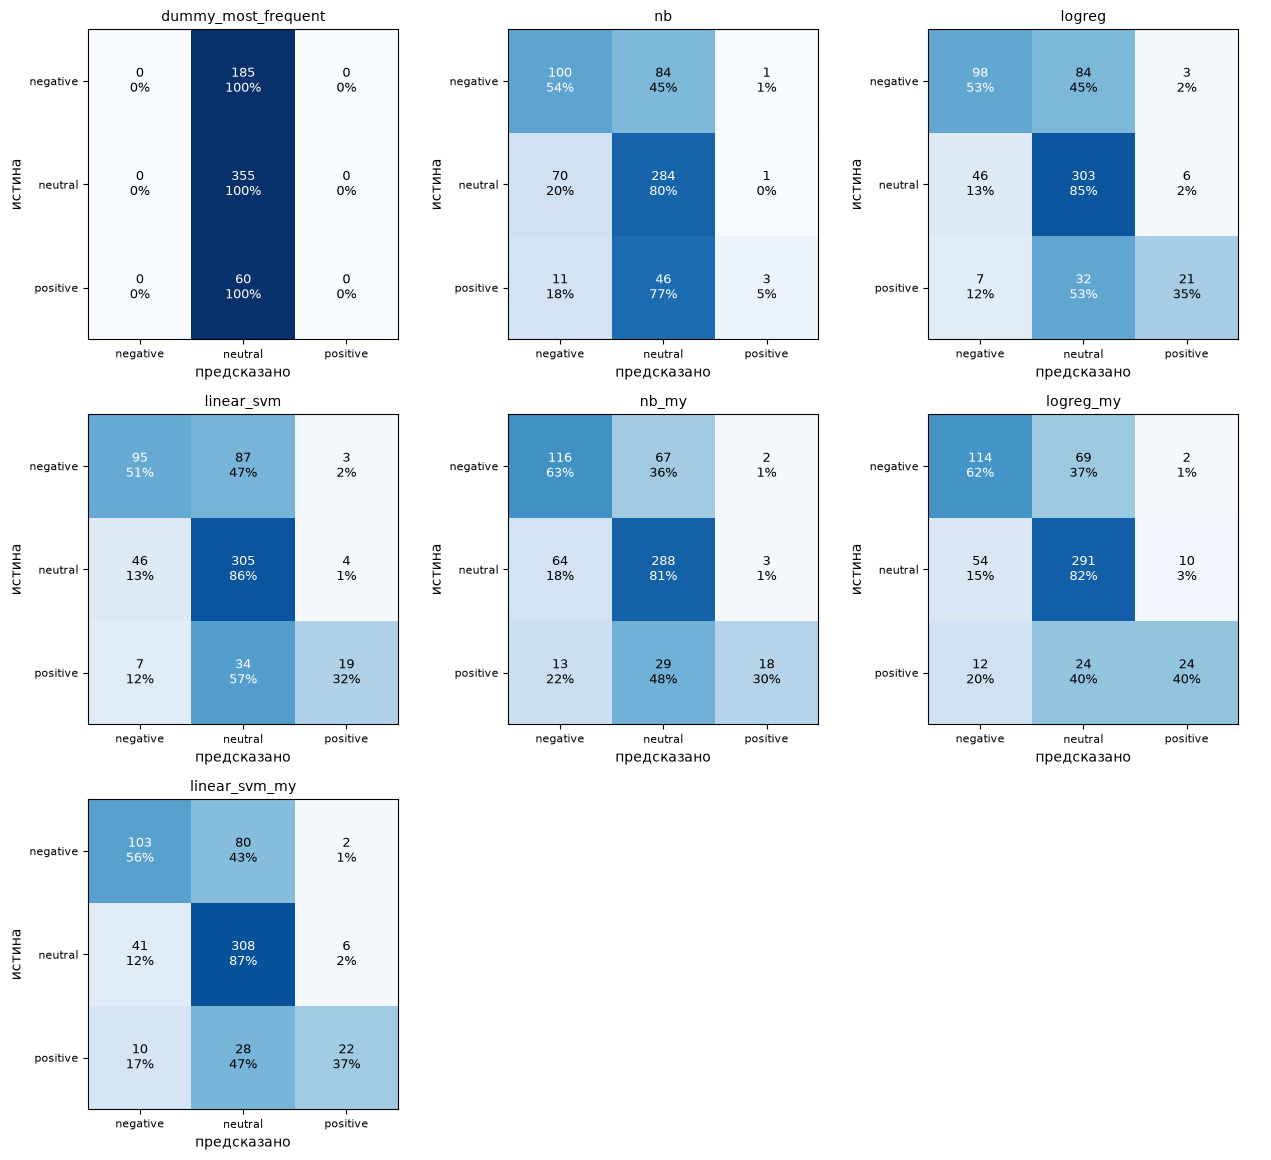

In [12]:
su.plot_confusions(test.reaction, test_pred, ncols=3)

### Примеры ошибок

In [ ]:
best = cv_table.sort_values("macro_f1").iloc[-1]["model"]
err = test[test.reaction != test_pred[best]].copy()
err["y_pred"] = test_pred[best][err.index]

print("Лучшая:", best, "| ошибок:", len(err))
for (t, p), g in err.groupby(["reaction", "y_pred"]):
    print(f"\n=== {t} → {p} ({len(g)}) ===")
    for s in g.raw_first.head(3): print("—", s[:200].replace("\n", " "))

Лучшая: logreg_my | ошибок: 171

=== negative → neutral (69) ===
— mass spectrometer, the length of AC rod will it affect to intensity? longer or shorter better?
— I have two voltage list like 100,99,99 (on state voltage) and 0,1,2 (off state voltage)as voltage input, and two time list like 5,6,4 (on state duration) and 2,2.5,3 (off state duration). it means sta
— I want you to make a “lore” to contain the meaning and context of what I provide into a confusing, old sounding, riddle-like, encrypted form that is told in third person with a large amount of those, 

=== negative → positive (2) ===
— how to answer positive this: To move forward with the onboarding process, we kindly request your timely confirmation of acceptance. Your prompt response would be sincerely appreciated. We sincerely lo
— it's me again. are you okay?

=== neutral → negative (54) ===
— How do i modify the table style in exel to remove the shading that appears on every other row.
— Develop parallel codes for the fo

### Сохранение моделей

In [17]:
OUT = "artifacts/reaction_models"
os.makedirs(OUT, exist_ok=True)

for name, model in fitted.items():
    path = os.path.join(OUT, f"reaction_{name}.joblib")
    joblib.dump(model, path)
    print("saved:", path)

saved: artifacts/reaction_models\reaction_dummy_most_frequent.joblib
saved: artifacts/reaction_models\reaction_nb.joblib
saved: artifacts/reaction_models\reaction_logreg.joblib
saved: artifacts/reaction_models\reaction_linear_svm.joblib
saved: artifacts/reaction_models\reaction_nb_my.joblib
saved: artifacts/reaction_models\reaction_logreg_my.joblib
saved: artifacts/reaction_models\reaction_linear_svm_my.joblib
